In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_csv("../data/clean_data/clean_dataset.csv")

In [4]:
df.describe()

,release_year
count,8790.000000
mean,2014.183163
std,8.825466
min,1925.000000
25%,2013.000000
50%,2017.000000
75%,2019.000000
max,2021.000000


In [5]:
df.shape

(8790, 10)

In [20]:
df.columns

Index(['show_id', 'type', 'title', 'director', 'country', 'date_added',
       'release_year', 'rating', 'duration', 'listed_in'],
      dtype='str')

In [19]:
df.groupby("type")["type"].value_counts()

type
Movie      6126
TV Show    2664
Name: count, dtype: int64

In [18]:
type_count = df["type"].value_counts()
type_persentage = round((type_count/len(df)) * 100,2)
type_persentage

type
Movie      69.69
TV Show    30.31
Name: count, dtype: float64

In [17]:
total_country = df["country"].value_counts().sort_values(ascending=False)
total_country.head()

country
United States     3240
India             1057
United Kingdom     638
Pakistan           421
Not Given          287
Name: count, dtype: int64

In [16]:
top_cetegory = df["listed_in"].value_counts().sort_values(ascending=False).head()
top_cetegory

listed_in
Dramas, International Movies                        362
Documentaries                                       359
Stand-Up Comedy                                     334
Comedies, Dramas, International Movies              274
Dramas, Independent Movies, International Movies    252
Name: count, dtype: int64

In [15]:
type_wise_country = df.groupby(["country","type"]).size().sort_values(ascending=False).head()
type_wise_country

country         type   
United States   Movie      2395
India           Movie       976
United States   TV Show     845
United Kingdom  Movie       387
Pakistan        TV Show     350
dtype: int64

In [14]:
df["director"].unique()

<StringArray>
[        'Kirsten Johnson',         'Julien Leclercq',
           'Mike Flanagan',           'Bruno Garotti',
            'Haile Gerima',         'Andy Devonshire',
          'Theodore Melfi',             'Suhas Kadav',
     'Christian Schwochow',               'Not Given',
 ...
 'Saratswadee Wongsomphet',       'Kirati Nakintanon',
             'Mark Risley',             'James Brown',
              'Ivona Juka',                  'Mu Chu',
 'Chandra Prakash Dwivedi',         'Majid Al Ansari',
            'Peter Hewitt',             'Mozez Singh']
Length: 4528, dtype: str

In [13]:
director_wise_movie_tv_shows = df.groupby(["type","director"]).size().sort_values(ascending=False).head()
director_wise_movie_tv_shows

type     director              
TV Show  Not Given                 2415
Movie    Not Given                  173
         Rajiv Chilaka               19
         Raúl Campos, Jan Suter      18
         Suhas Kadav                 16
dtype: int64

In [12]:
df[df["type"] == "Movie"]["director"].value_counts().head()

director
Not Given                 173
Rajiv Chilaka              19
Raúl Campos, Jan Suter     18
Suhas Kadav                16
Marcus Raboy               15
Name: count, dtype: int64

In [11]:
release_year_wise = df.groupby(["release_year","type"]).size().unstack(fill_value=0).sort_values(by=["Movie","TV Show"],ascending=False).head()
release_year_wise

type,Movie,TV Show
release_year,,
2018,767,379
2017,765,265
2016,658,243
2019,633,397
2020,517,436


In [10]:
top_director = df[df["director"].notna() & (df["director"] != "Not Given")].groupby(["director","release_year"]).size().reset_index(name="title_count").sort_values(by="title_count",ascending=False).head(10)
top_director

,director,release_year,title_count
4445,"Raúl Campos, Jan Suter",2018,12
3295,Marcus Raboy,2017,6
4364,Rajiv Chilaka,2013,6
1999,Hidenori Inoue,2017,5
2914,"Krysia Plonka, Kristian Mercado",2021,5
2256,Jay Chapman,2017,4
3437,Matt Askem,2018,4
1625,Fernando Ayllón,2019,4
1463,Edward Cotterill,2017,4
2692,Justin G. Dyck,2018,4


In [9]:
rating_wise_type = df.groupby(["rating","type"]).size().unstack(fill_value=0).sort_values(by=["Movie","TV Show"],ascending=False)
rating_wise_type

type,Movie,TV Show
rating,,
TV-MA,2062,1143
TV-14,1427,730
R,797,2
TV-PG,540,321
PG-13,490,0
PG,287,0
TV-Y7,139,194
TV-Y,131,175
TV-G,126,94


In [8]:
add_content = pd.to_datetime(df["date_added"]).dt.year.value_counts().sort_index(ascending=False)
add_content

date_added
2021    1498
2020    1879
2019    2016
2018    1648
2017    1185
2016     426
2015      82
2014      24
2013      11
2012       3
2011      13
2010       1
2009       2
2008       2
Name: count, dtype: int64

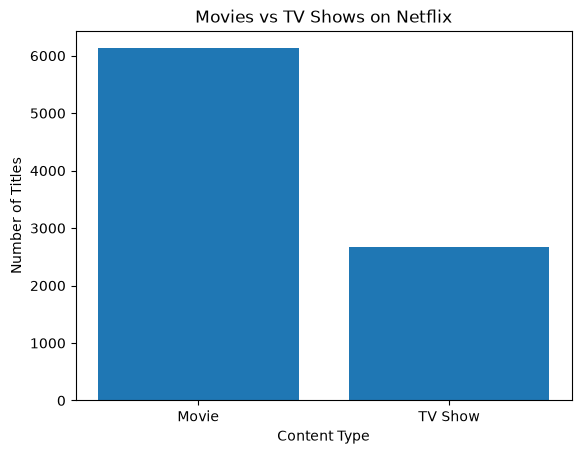

In [7]:
content_count = df["type"].value_counts()
plt.Figure(figsize=(6,4))
plt.bar(content_count.index,content_count.values)
plt.title("Movies vs TV Shows on Netflix")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")
plt.show()

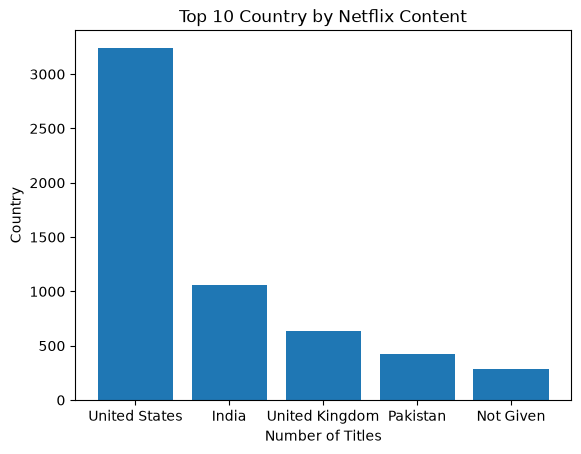

In [22]:
total_country = total_country.head()
plt.Figure(figsize=(6,4))
plt.bar(total_country.index,total_country.values)
plt.title("Top 10 Country by Netflix Content")
plt.xlabel("Number of Titles")
plt.ylabel("Country")
plt.show()

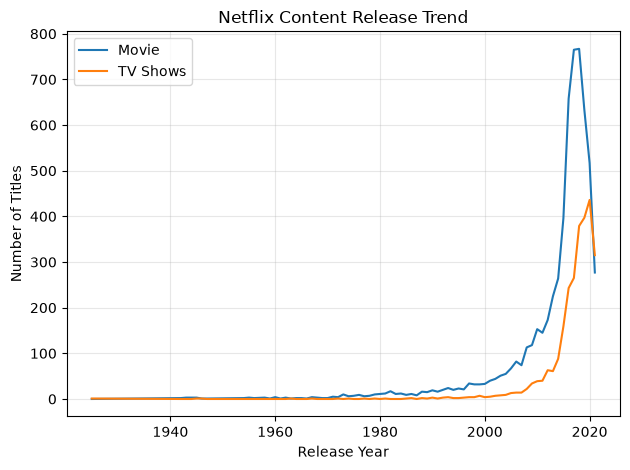

In [24]:
yearly_content = df.groupby(["release_year","type"]).size().unstack(fill_value=0)
plt.Figure(figsize=(12,6))
plt.plot(
    yearly_content.index,
    yearly_content["Movie"],
    label="Movie"
)
plt.plot(
    yearly_content.index,
    yearly_content["TV Show"],
    label="TV Shows"
)
plt.title("Netflix Content Release Trend")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.legend()
plt.grid(True,alpha=0.3)
plt.tight_layout()
plt.show()

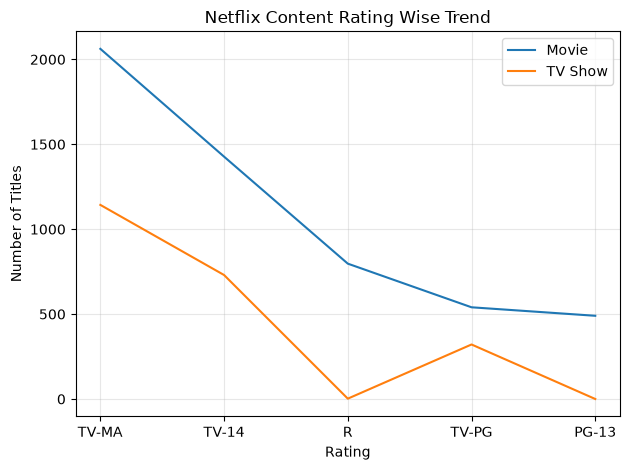

In [31]:
rating_wise_type = rating_wise_type.head()
plt.Figure(figsize=(12,6))
plt.plot(
    rating_wise_type.index,
    rating_wise_type["Movie"],
    label="Movie"
)
plt.plot(
    rating_wise_type.index,
    rating_wise_type["TV Show"],
    label="TV Show"
)
plt.title("Netflix Content Rating Wise Trend")
plt.xlabel("Rating")
plt.ylabel("Number of Titles")
plt.legend()
plt.grid(True,alpha=0.3)
plt.tight_layout()
plt.show()

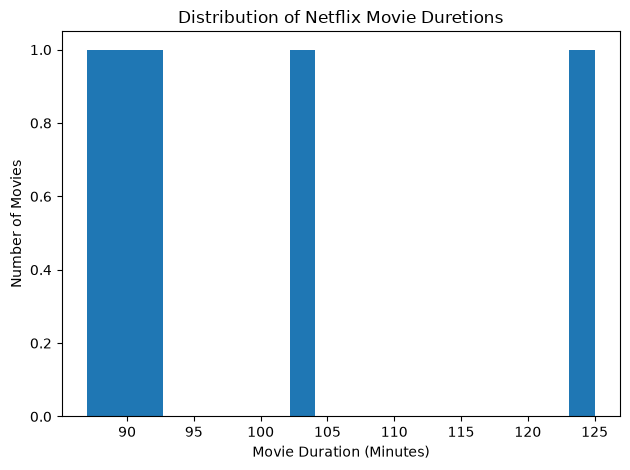

In [55]:
movies_df = df[df["type"] == "Movie"].copy()
movies_df["duration_minuts"] = (
    movies_df["duration"].str.extract(r"(\d+)").astype(float).head())
plt.Figure(figsize=(10,5))
plt.hist(movies_df["duration_minuts"].dropna(),bins=20)
plt.title("Distribution of Netflix Movie Duretions")
plt.xlabel("Movie Duration (Minutes)")
plt.ylabel("Number of Movies")
plt.tight_layout()
plt.show()

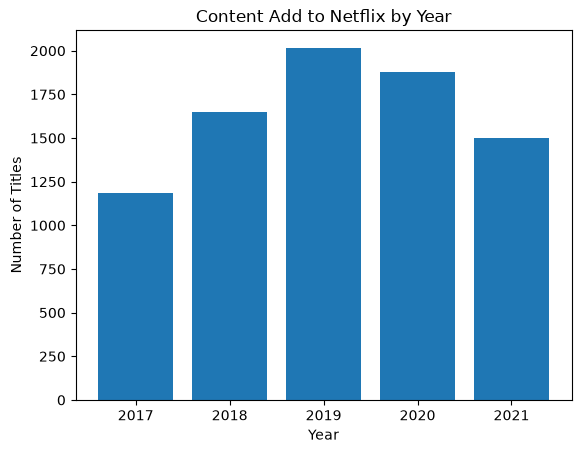

In [60]:
add_content = add_content.head()
plt.Figure(figsize=(6,4))
plt.bar(add_content.index,add_content.values)
plt.title("Content Add to Netflix by Year")
plt.xlabel("Year")
plt.ylabel("Number of Titles")
plt.show()

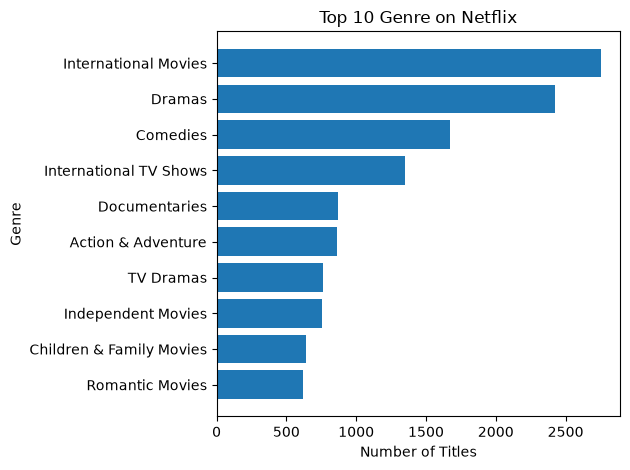

In [64]:
genre_counts = (
    df["listed_in"].dropna().str.split(",").explode().str.strip().value_counts().head(10).sort_values()
)

plt.Figure(figsize=(12,7))
plt.barh(genre_counts.index,genre_counts.values)
plt.title("Top 10 Genre on Netflix")
plt.xlabel("Number of Titles")
plt.ylabel("Genre")
plt.tight_layout()
plt.show()

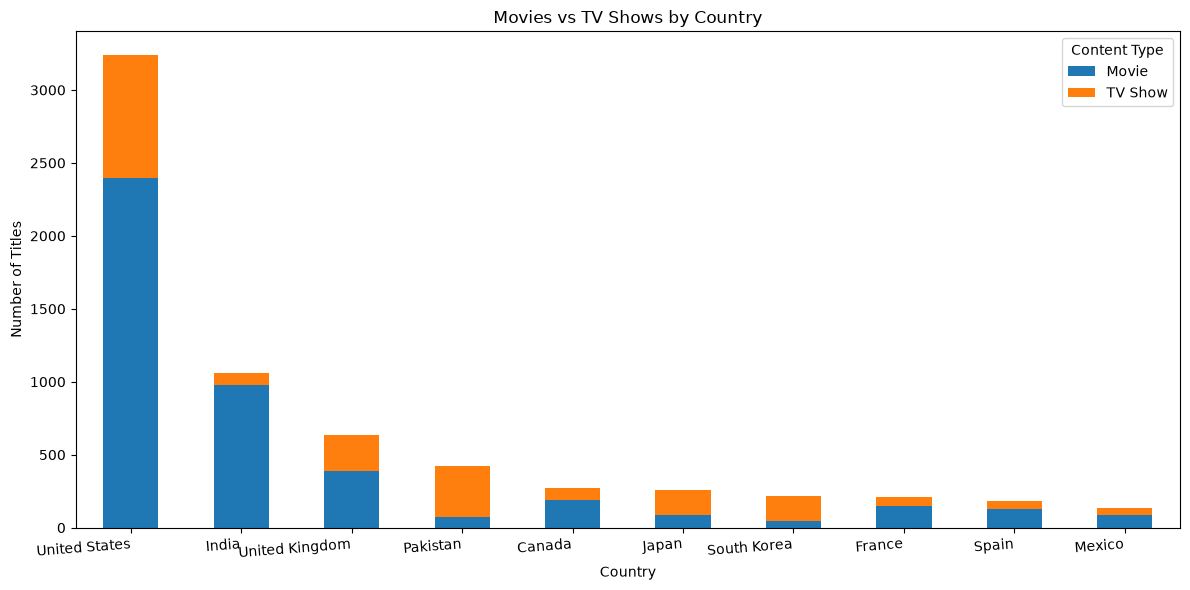

In [74]:
contry_wise_trend = (df[df["country"].notna() & (df["country"] != "Not Given")][["country","type"]]
                     .groupby(["country","type"]).size().unstack(fill_value=0))
top_countries = contry_wise_trend.sum(axis=1).nlargest(10).index
top_country_type = contry_wise_trend.loc[top_countries]
top_country_type.plot(
    kind="bar",
    stacked=True,
    figsize=(12,6)
)

plt.title("Movies vs TV Shows by Country")
plt.xlabel("Country")
plt.ylabel("Number of Titles")
plt.xticks(rotation=4.5,ha="right")
plt.legend(title="Content Type")
plt.tight_layout()
plt.show()

Content Distribution: Movies aur tv shows ka comparition
Country Analysis: sabse zyada content wali countries
Release trend: kis release year mein content zyada tha
Genre Analysis: top individual genre
Director Analysis: sabse zyada titles wale directors
Movie Duration: Movies ki common duration range
Content Addition Trend: Netflix par kis year mein sabse zyada titles add hue